# LLM training (run 11, phases 1 and 3)

Thesis figures for the reader (phase 1) or the joint fine-tune (phase 3) of run 11. The notebook
reads the run from the folder it sits in (`diagrams/data/<run name>/`), so the same notebook
serves both runs; diagrams that only exist in one of them are skipped in the other.

- **Reader:** Qwen3-14B (frozen) + LoRA r16 + prefix adapter. Input is the paper's own embedding,
  or with probability 0.5 the mean of its references' embeddings. 6 epochs of 15,000 papers.
- **Joint:** the reader continued with the GNN estimate as input. LM loss plus
  $1\cdot(1-\cos)$ between the GNN estimate and the own embedding. GNN learning rate $10^{-5}$.
  3 epochs.

What is logged:
- one optimiser step = 16 papers; training metrics every 10 steps;
- validation loss every 250 steps and at each epoch end, with the prefix on and with the gate
  forced to 0;
- identification (`val_id`) once per epoch: the model writes 96 tokens for 128 fixed validation
  papers, and each text is ranked against their 128 gold abstracts.

Every diagram is its own file under `figures/`, as PDF for LaTeX and PNG for previews. Figures
are drawn at their printed size, so include them without a `width=` option. Dotted vertical
lines mark epoch boundaries; the top axis counts epochs.

Two W&B keys have no figure of their own:
- `valid/best` is the selection metric, the same numbers as one arm's `val_id` MRR;
- `valid/bad_epochs` is the early-stopping counter.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, PercentFormatter, FuncFormatter

RUN_DIR = Path.cwd()                          # diagrams/data/<run name>/
sys.path.insert(0, str(RUN_DIR.parents[1]))   # diagrams/, for thesis_style
import thesis_style as ts

ts.apply()
# Printed size of every figure: 0.75 \textwidth matches the template's caption width.
# ts.TEXTWIDTH = full width, ts.HALFWIDTH = two subfigures side by side.
ts.FIGWIDTH, ts.FIGHEIGHT = 0.75 * ts.TEXTWIDTH, 70 * ts.MM
C = ts.COLORS
OUT = RUN_DIR / "figures"

RUN = RUN_DIR.name
SHORT = RUN.removeprefix("run11-").removesuffix("-14541449")   # reader / joint
config = json.loads((RUN_DIR / "config.json").read_text())
history = pd.read_csv(RUN_DIR / "history.csv")
hist_path = RUN_DIR / "histograms.json"
gate_hist = json.loads(hist_path.read_text()) if hist_path.exists() else []

STEPS_PER_EPOCH = config["epoch_size"] / config["effective_batch_size"]   # 937.5
train = history.dropna(subset=["train/loss"])
valid = history.dropna(subset=["valid/graph"])
epochs = history.dropna(subset=["valid/best"]).reset_index(drop=True)    # one row per epoch
epochs["epoch"] = np.arange(1, len(epochs) + 1)

# val_id arms: reader = own embedding + reference mean, joint = GNN estimate + reference mean.
ARMS = [a for a in ("oracle", "gnn", "refs") if f"val_id/{a}_mrr" in history]
ARM_LABEL = {"oracle": "Own embedding", "refs": "Reference mean", "gnn": "GNN estimate"}
ARM_COLOR = {"oracle": C["blue"], "refs": C["orange"], "gnn": C["green"]}
ARM_MARKER = {"oracle": "o", "refs": "s", "gnn": "^"}
SELECT_ARM = "gnn" if config["joint"] else "refs"   # what valid/best tracks (selection_score)
best = epochs.loc[epochs["valid/best"].idxmax()]
N_VAL_ID = 128
RING = dict(ls="none", marker="o", ms=9, mfc="none", mec=C["black"], mew=0.9, zorder=3)

def smooth(s, window=10):
    # 10 logged points = 100 optimiser steps = 1,600 papers
    return s.rolling(window, center=True, min_periods=1).mean()

HALF = dict(width=ts.HALFWIDTH, height=62 * ts.MM)   # thesis Ch. 7: two figures side by side

def step_figure(ylabel, **size):
    # A diagram over optimiser steps, with epoch boundaries and an epoch axis on top.
    fig, ax = ts.figure(**size)
    for e in range(1, config["epochs"]):
        ax.axvline(e * STEPS_PER_EPOCH, color=C["grey"], lw=0.5, ls=":", zorder=0)
    top = ax.secondary_xaxis("top", functions=(lambda s: s / STEPS_PER_EPOCH,
                                               lambda e: e * STEPS_PER_EPOCH))
    top.xaxis.set_major_locator(MaxNLocator(integer=True))
    top.tick_params(labelsize=7, length=2)
    top.set_xlabel("Epoch", fontsize=8)
    ax.set_xlim(0, config["epochs"] * STEPS_PER_EPOCH)
    ax.set_xlabel("Optimiser step")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1000:g}k" if x else "0"))
    ax.set_ylabel(ylabel)
    return fig, ax

def raw_and_smoothed(ax, key, color=C["blue"], light=C["sky"], label=None):
    ax.plot(train._step, train[key], color=light, lw=0.5, alpha=0.6)
    ax.plot(train._step, smooth(train[key]), color=color, lw=1.3, label=label)

print(f"{RUN}: {len(train)} training points, {len(valid)} validation points, {len(epochs)} epochs, "
      f"{len(gate_hist)} gate histograms")
print(f"  selected epoch {int(best.epoch)} (val_id MRR of the {ARM_LABEL[SELECT_ARM].lower()} arm "
      f"{best['valid/best']:.3f})")

run11-reader-14541449: 562 training points, 28 validation points, 6 epochs, 562 gate histograms
  selected epoch 5 (val_id MRR of the reference mean arm 0.530)


## Language-model loss

Training loss: thin line raw (each point averages 10 optimiser steps), thick line a centred
moving average over 100 steps. Validation loss on the 806 validation papers, with the prefix on
and with the gate set to 0 (the graph channel disconnected). The gap between the two
validation curves is what the vector contributes.

*Suggested caption:* Language-model loss of the [reader / joint fine-tune]. Training loss
(smoothed over 100 optimiser steps) and validation loss with the graph prefix on and off
(gate $=0$).

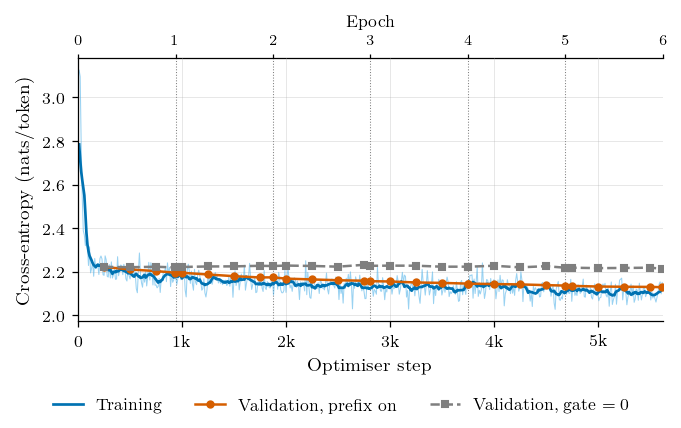

In [2]:
fig, ax = step_figure("Cross-entropy (nats/token)")
raw_and_smoothed(ax, "train/loss", label="Training")
ax.plot(valid._step, valid["valid/graph"], "o-", color=C["vermillion"], ms=3,
        label="Validation, prefix on")
ax.plot(valid._step, valid["valid/gate0"], "s--", color=C["grey"], ms=3,
        label=r"Validation, gate $=0$")
ts.legend_below(fig)
ts.save(fig, f"{SHORT}_loss", OUT)
plt.show()

## Loss reduction from the prefix

Validation loss with the gate at 0 minus with the prefix on, in nats per token: how much the
vector lowers the loss.

*Suggested caption:* Reduction in validation loss when the graph prefix is on rather than gated
off, during [reader / joint] training.

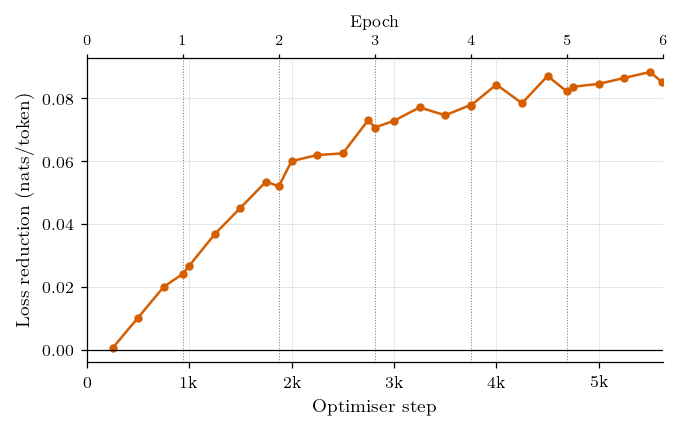

In [3]:
fig, ax = step_figure("Loss reduction (nats/token)")
ax.plot(valid._step, valid["valid/delta"], "o-", color=C["vermillion"], ms=3)
ax.axhline(0, color=C["black"], lw=0.6)
ts.save(fig, f"{SHORT}_loss_reduction", OUT)
plt.show()

## Gate magnitude

The 80 learned gate scalars scale the graph's contribution to the prefix. They are initialised
at 0. Shown: their mean and maximum absolute value.

*Suggested caption:* Mean and maximum absolute value of the 80 prefix gates during
[reader / joint] training.

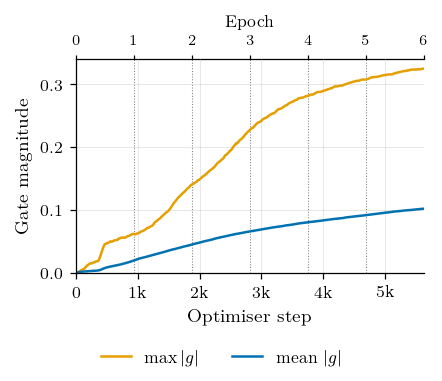

In [4]:
fig, ax = step_figure("Gate magnitude", **HALF)
ax.plot(train._step, train["gate/max_abs"], color=C["orange"], label=r"$\max |g|$")
ax.plot(train._step, train["gate/mean_abs"], color=C["blue"], label=r"mean $|g|$")
ax.set_ylim(bottom=0)
ts.legend_below(fig, ncol=2)
ts.save(fig, f"{SHORT}_gate_magnitude", OUT)
plt.show()

## Distribution of the gate values

W&B stored `gate/per_layer` as a 64-bin histogram of the 80 gate values every 10 steps. The
percentiles are read off each histogram (linear interpolation within a bin; bins are ~0.01
wide). Shown:
- shaded: 5th–95th and 25th–75th percentile;
- line: median;
- thin lines: smallest and largest gate.

The gates start at 0 and spread in both directions. The sign only sets the direction of the
graph's contribution in that position.

*Suggested caption:* Distribution of the 80 gate values during [reader / joint] training:
median, interquartile range, 5th–95th percentile and extremes.

gates per histogram: [80]


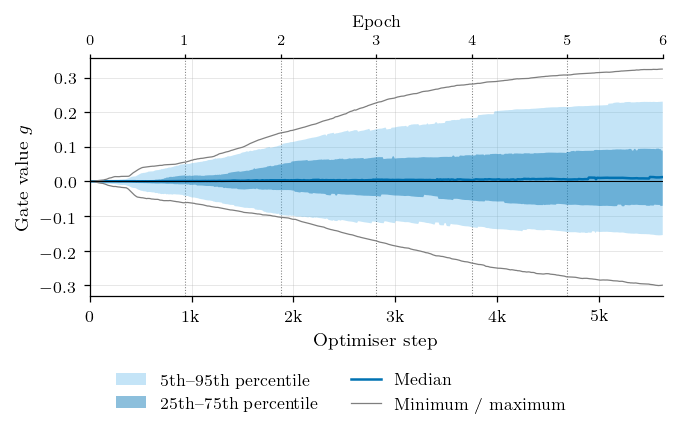

In [5]:
def quantiles(h, qs):
    # Percentiles of one W&B packed histogram, interpolating linearly inside a bin.
    pb = h["packedBins"]
    edges = pb["min"] + pb["size"] * np.arange(pb["count"] + 1)
    counts = np.asarray(h["values"], dtype=float)
    cdf = np.concatenate([[0], np.cumsum(counts)]) / counts.sum()
    return np.interp(qs, cdf, edges), edges[np.nonzero(counts)[0][[0, -1]] + [0, 1]]

if not gate_hist:
    print("no gate histograms in this run")
else:
    QS = [0.05, 0.25, 0.5, 0.75, 0.95]
    steps = np.array([h["_step"] for h in gate_hist])
    q, ext = zip(*(quantiles(h["gate/per_layer"], QS) for h in gate_hist))
    q, ext = np.array(q), np.array(ext)
    print(f"gates per histogram: {sorted({int(sum(h['gate/per_layer']['values'])) for h in gate_hist})}")

    fig, ax = step_figure(r"Gate value $g$")
    ax.fill_between(steps, q[:, 0], q[:, 4], color=C["sky"], alpha=0.35, lw=0,
                    label="5th–95th percentile")
    ax.fill_between(steps, q[:, 1], q[:, 3], color=C["blue"], alpha=0.45, lw=0,
                    label="25th–75th percentile")
    ax.plot(steps, q[:, 2], color=C["blue"], lw=1.2, label="Median")
    ax.plot(steps, ext[:, 0], color=C["grey"], lw=0.6, label="Minimum / maximum")
    ax.plot(steps, ext[:, 1], color=C["grey"], lw=0.6)
    ax.axhline(0, color=C["black"], lw=0.5)
    ts.legend_below(fig, ncol=2)
    ts.save(fig, f"{SHORT}_gate_distribution", OUT)
    plt.show()

## Identification of the generated text (model selection)

At the end of each epoch the model writes 96 tokens for 128 fixed validation papers, from each
input arm. Each text is ranked against those papers' 128 gold abstracts by TF-IDF. Shown:
- top-1: share of texts whose own gold ranks first;
- MRR: mean reciprocal rank.

The dotted line is chance: 1/128 = 0.78% for top-1, and $H_{128}/128 = 0.043$ for MRR. The
ring marks the epoch kept as `best.pt`, selected on the MRR of the reference-mean arm (reader)
or the GNN arm (joint).

*Suggested caption:* Top-1 identification [mean reciprocal rank] of generated text among 128
validation papers after each epoch of [reader / joint] training, per input. Dotted: chance.

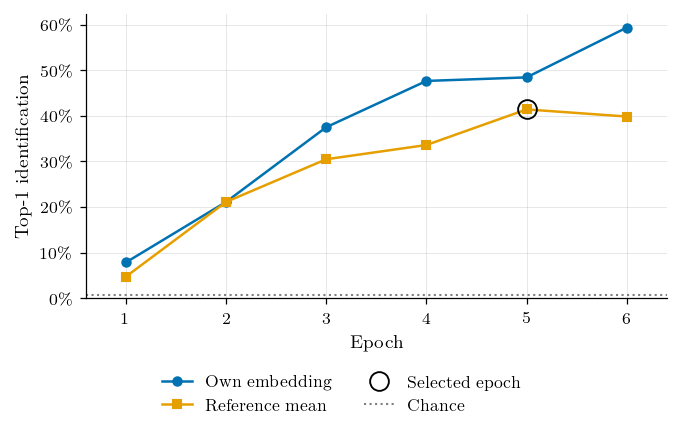

In [6]:
def identification(metric, ylabel, chance, pct, **size):
    scale = 100 if pct else 1
    fig, ax = ts.figure(**size)
    for arm in ARMS:
        ax.plot(epochs.epoch, scale * epochs[f"val_id/{arm}_{metric}"], color=ARM_COLOR[arm],
                marker=ARM_MARKER[arm], ms=4, label=ARM_LABEL[arm])
    ax.plot(best.epoch, scale * best[f"val_id/{SELECT_ARM}_{metric}"], label="Selected epoch",
            **RING)
    ax.axhline(scale * chance, color=C["grey"], ls=":", lw=1, label="Chance")
    ax.set(xlabel="Epoch", ylabel=ylabel, xlim=(0.6, len(epochs) + 0.4))
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    if pct:
        ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ts.legend_below(fig, ncol=2)
    ts.save(fig, f"{SHORT}_identification_{metric}", OUT)
    plt.show()

identification("top1", "Top-1 identification", 1 / N_VAL_ID, pct=True)

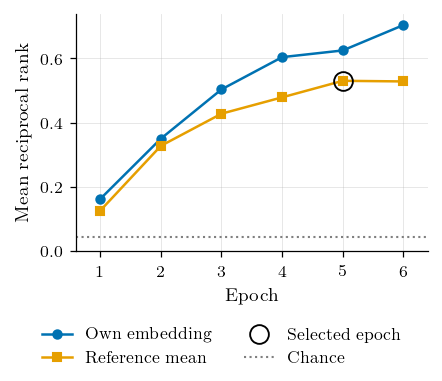

In [7]:
identification("mrr", "Mean reciprocal rank",
               np.sum(1 / np.arange(1, N_VAL_ID + 1)) / N_VAL_ID, pct=False, **HALF)

## Prefix amplitude

$\lVert g\odot\delta\rVert / \lVert\text{base}\rVert$: how large the graph's contribution to the
prefix is, relative to the paper-independent base prefix. It is a snapshot from one batch
(thin), with a 100-step moving average (thick).

*Suggested caption:* Relative amplitude of the graph contribution to the prefix during
[reader / joint] training.

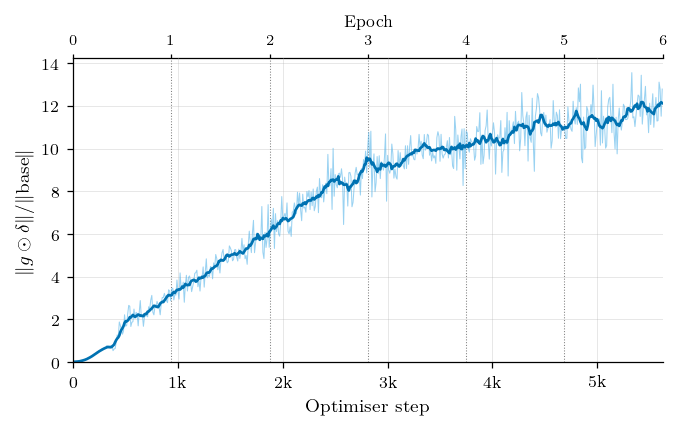

In [8]:
fig, ax = step_figure(r"$\lVert g\odot\delta\rVert / \lVert \mathrm{base}\rVert$")
raw_and_smoothed(ax, "prefix/graph_fraction")
ax.set_ylim(bottom=0)
ts.save(fig, f"{SHORT}_prefix_amplitude", OUT)
plt.show()

## Prefix contrast

Mean pairwise cosine between the graph contributions of 64 fixed probe papers. 1 would mean
every paper gets the same prefix, however large it is.

*Suggested caption:* Mean pairwise cosine between the graph contributions to the prefix of 64
probe papers during [reader / joint] training.

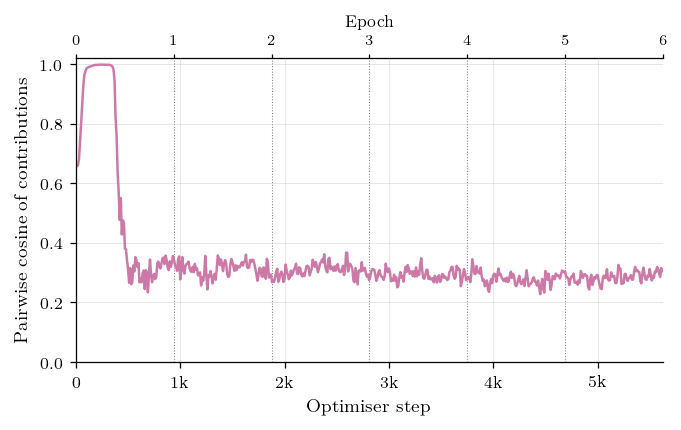

In [9]:
fig, ax = step_figure("Pairwise cosine of contributions")
ax.plot(train._step, train["prefix/graph_contrast"], color=C["purple"])
ax.set_ylim(0, 1.02)
ts.save(fig, f"{SHORT}_prefix_contrast", OUT)
plt.show()

## Canary: distinct generations

The number of distinct 48-token openings the model writes for 16 fixed validation papers,
every 250 steps and at each epoch end. 16 means no two collapse onto the same text.

*Suggested caption:* Distinct generations among 16 canary validation papers during
[reader / joint] training.

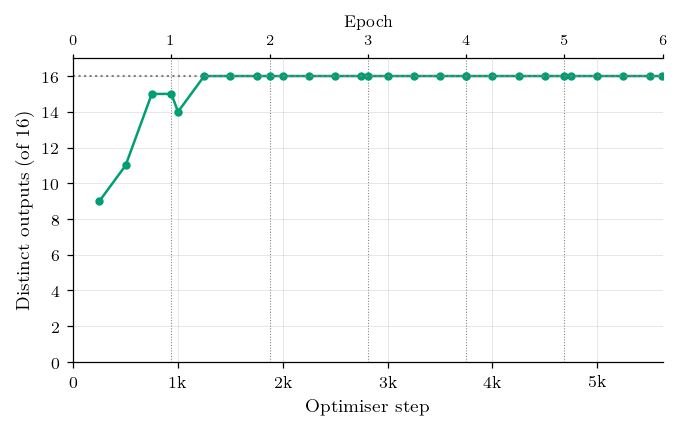

In [10]:
canary = history.dropna(subset=["canary/distinct"])
fig, ax = step_figure("Distinct outputs (of 16)")
ax.plot(canary._step, canary["canary/distinct"], "o-", color=C["green"], ms=3)
ax.axhline(16, color=C["grey"], ls=":", lw=1)
ax.set_ylim(0, 17)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ts.save(fig, f"{SHORT}_canary", OUT)
plt.show()

## GNN output diversity

`encoder/output_cosine` is the mean pairwise cosine between the input vectors of the 64 probe
papers:
- in the reader they are the own embeddings, so the value is constant;
- in the joint run they are the GNN estimates.

*Suggested caption:* Mean pairwise cosine between the GNN estimates of 64 probe papers during
the joint fine-tune.

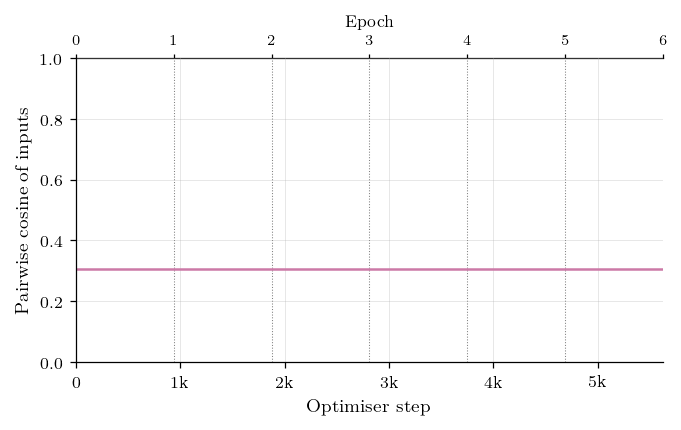

In [11]:
fig, ax = step_figure("Pairwise cosine of inputs")
ax.plot(train._step, train["encoder/output_cosine"], color=C["purple"])
ax.set_ylim(0, 1)
ts.save(fig, f"{SHORT}_input_cosine", OUT)
plt.show()

## GNN imitation loss (joint run only)

$1-\cos$ between the GNN estimate and the paper's own embedding, averaged over the training
papers of each 10-step window. If this curve is flat, the GNN did not move at learning rate
$10^{-5}$.

*Suggested caption:* GNN imitation loss $1-\cos(\hat{z}, z)$ during the joint fine-tune,
smoothed over 100 optimiser steps.

In [12]:
if "train/cos_loss" not in history:
    print("train/cos_loss is only logged by the joint fine-tune")
else:
    fig, ax = step_figure(r"$1-\cos(\hat{z}, z)$", **HALF)
    raw_and_smoothed(ax, "train/cos_loss")
    ts.save(fig, f"{SHORT}_gnn_cos_loss", OUT)
    plt.show()

train/cos_loss is only logged by the joint fine-tune


## Optimisation: learning rate, gradient norm, throughput

- Learning rate: linear warm-up over 100 steps, then constant (no decay).
- Gradient norm: before clipping.
- Throughput: supervised tokens per second. It has spikes at the logging steps right after each
  validation. These are an artefact of how it was measured: the timer restarts after
  validation but the token count does not. The y-axis is clipped at 1.5× the median so the
  spikes do not set the scale.

*Suggested caption:* Learning rate [pre-clipping gradient norm / training throughput] of the
[reader / joint] run.

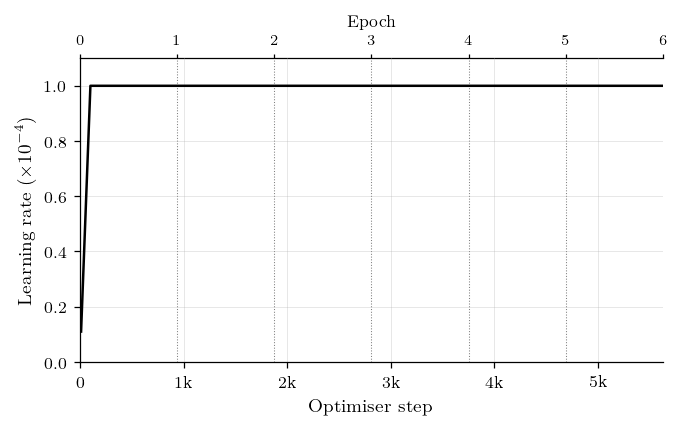

In [13]:
fig, ax = step_figure(r"Learning rate ($\times 10^{-4}$)")
ax.plot(train._step, 1e4 * train["train/lr"], color=C["black"])
ax.set_ylim(0, 1.1e4 * train["train/lr"].max())
ts.save(fig, f"{SHORT}_learning_rate", OUT)
plt.show()

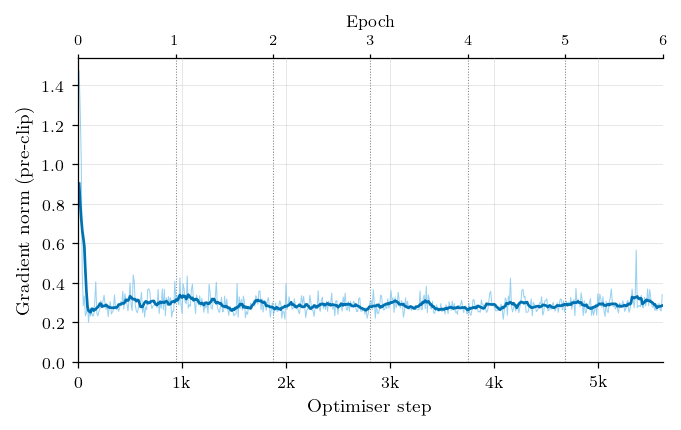

In [14]:
fig, ax = step_figure("Gradient norm (pre-clip)")
raw_and_smoothed(ax, "train/grad_norm")
ax.set_ylim(bottom=0)
ts.save(fig, f"{SHORT}_grad_norm", OUT)
plt.show()

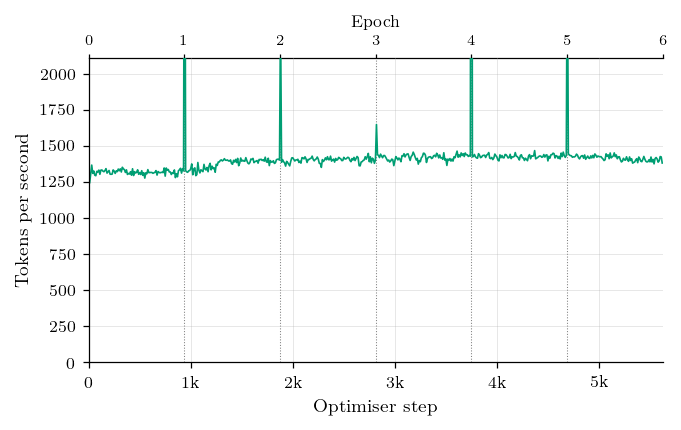

In [15]:
fig, ax = step_figure("Tokens per second")
ax.plot(train._step, train["train/tokens_per_sec"], color=C["green"], lw=0.8)
ax.set_ylim(0, 1.5 * train["train/tokens_per_sec"].median())
ts.save(fig, f"{SHORT}_throughput", OUT)
plt.show()

## Thesis Ch. 7: three panels in one row

One full-width figure per training phase, to save space in the thesis (author, 2026-11-17):
(a) training and validation loss (prefix on only), (b) identification MRR per epoch,
(c) gate magnitude (reader) or the GNN imitation loss (joint). Panel letters sit under the
x-axis labels.

*Suggested caption:* Phase [1 / 3] training. (a) Next-token loss … (b) Identification MRR …
(c) …

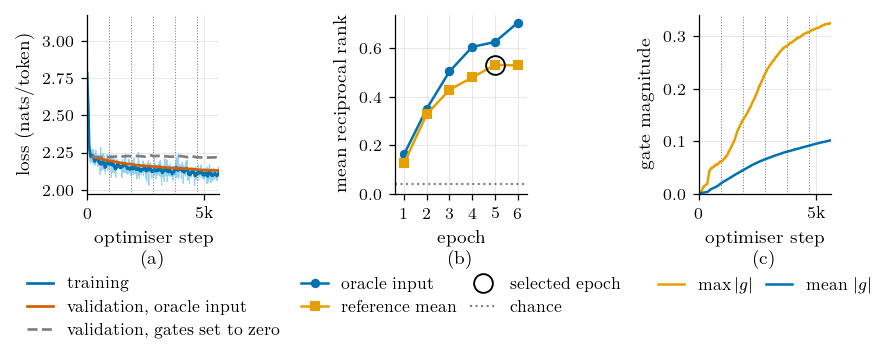

In [16]:
def epoch_lines(ax):
    for e in range(1, config["epochs"]):
        ax.axvline(e * STEPS_PER_EPOCH, color=C["grey"], lw=0.5, ls=":", zorder=0)
    ax.set_xlim(0, config["epochs"] * STEPS_PER_EPOCH)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1000:g}k" if x else "0"))

def panel_legend(ax, ncol=1):
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.38), ncol=ncol, frameon=False,
              handlelength=1.6, columnspacing=0.8)

fig, (a, b, c) = plt.subplots(1, 3, figsize=(ts.TEXTWIDTH - 2 * ts.MM, 58 * ts.MM), layout="constrained")

epoch_lines(a)
raw_and_smoothed(a, "train/loss", label="training")
VAL_INPUT = "GNN estimate" if config["joint"] else "oracle input"
a.plot(valid._step, valid["valid/graph"], "-", color=C["vermillion"], lw=1.3,
       label=f"validation, {VAL_INPUT}")
a.plot(valid._step, valid["valid/gate0"], "--", color=C["grey"], lw=1.3,
       label="validation, gates set to zero")
a.set(xlabel="optimiser step\n(a)", ylabel="loss (nats/token)")
panel_legend(a)

for arm in ARMS:
    b.plot(epochs.epoch, epochs[f"val_id/{arm}_mrr"], color=ARM_COLOR[arm],
           marker=ARM_MARKER[arm], ms=3.5, label={"oracle": "oracle input", "refs": "reference mean", "gnn": "GNN estimate"}[arm])
b.plot(best.epoch, best[f"val_id/{SELECT_ARM}_mrr"], label="selected epoch", **RING)
b.axhline(np.sum(1 / np.arange(1, N_VAL_ID + 1)) / N_VAL_ID, color=C["grey"], ls=":", lw=1, label="chance")
b.set(xlabel="epoch\n(b)", ylabel="mean reciprocal rank", xlim=(0.6, len(epochs) + 0.4))
b.set_ylim(bottom=0)
b.xaxis.set_major_locator(MaxNLocator(integer=True))
panel_legend(b, ncol=2)

epoch_lines(c)
if config["joint"]:
    raw_and_smoothed(c, "train/cos_loss")
    c.set(xlabel="optimiser step\n(c)", ylabel="training cosine loss")
else:
    c.plot(train._step, train["gate/max_abs"], color=C["orange"], label=r"$\max |g|$")
    c.plot(train._step, train["gate/mean_abs"], color=C["blue"], label=r"mean $|g|$")
    c.set(xlabel="optimiser step\n(c)", ylabel="gate magnitude")
    c.set_ylim(bottom=0)
    panel_legend(c, ncol=2)

# The legends hang below the axes, outside what constrained layout reserves, so the PDF clipped
# the bottom legend row and the left label (author, 2026-11-17): save to the drawn content instead.
for ext in ("pdf", "png"):
    fig.savefig(f"{OUT}/{SHORT}_overview.{ext}", bbox_inches="tight", pad_inches=0.5 * ts.MM)
plt.show()